# Compare the original SAC agent with your SAC implementation

This notebook separates **reproducing the original training entry point** from **comparing both implementations under one common training/evaluation schedule**. Original source and notebooks are not modified.

Your implementation uses two Q critics + two target Q critics, Gaussian log-standard-deviation outputs, fixed entropy coefficient 0.2, hidden widths 256/128, Adam 3e-4. The original uses two Q critics + value + target value, directly clamped standard deviations [0.03,0.15], implicit entropy coefficient 1, and the settings in SAC_CONFIG. Comparing these defaults compares implementation packages, not a single architectural change.

The comparison uses the same HFSS channel, environment/reward, reset seeds, interaction budget, warmup distribution, batch size, update count and terminal-mask convention. Evaluation is deterministic and uses a separate environment. Final-step and best-feasible-intermediate results are reported separately; infeasible trials remain explicit failures.

No training is run automatically. Configure the paths, run the definition cells, run the smoke check, then deliberately launch an experiment.


In [1]:
import sys, json, copy, random, hashlib
from pathlib import Path
from collections import deque
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT)) if str(PROJECT_ROOT) not in sys.path else None
from src.env import NearFieldBeamFocusingEnv
from src.sac_agent import SACAgent as OriginalSACAgent
from src.config import ENV_CONFIG, SAC_CONFIG, TRAIN_CONFIG, HFSS_FILE
from src.utils import load_hfss_channel

CHANNEL_FILE = Path(HFSS_FILE)  # Set to the real .s24p file if it is elsewhere.
RESULTS_DIR = Path('comparison_results')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Common schedule. 500 episodes of 60 steps = 30,000 interactions in SAC_only.
TOTAL_STEPS = 500 * int(ENV_CONFIG['max_steps'])
LEARNING_STARTS = int(TRAIN_CONFIG['initial_random_steps'])
UPDATES_PER_STEP = int(TRAIN_CONFIG['updates_per_step'])
BATCH_SIZE = int(SAC_CONFIG['batch_size'])
EVAL_EVERY = 5_000
VALIDATION_SEEDS = list(range(10_000, 10_010))
TEST_SEEDS = list(range(20_000, 20_100))
# True reproduces src/train.py's use of terminated OR truncated in replay.
# False uses only genuine termination. Set identically for both agents.
MASK_TIME_LIMITS = True


## 1. Reproduce the original entry point (optional, separate experiment)

SAC_only runs a preliminary episode that fills replay, then 500 training episodes without the configured warmup. It is not the same experiment as src/train.py. The actual entry point uses TRAIN_CONFIG (currently 2,000 episodes), warmup and validation-based checkpointing.

The optional call below runs that original entry point, including its plotting and checkpoint writes. Point the project's HFSS_FILE configuration at your real channel first. It does not use CHANNEL_FILE from this notebook. Do not run it inside the comparison loop.


In [2]:
# from src.train import train as reproduce_original
# original_history = reproduce_original()


## 2. Your networks and replay buffer
Copied from SAC_search_scratch; algorithmic losses are preserved. Training state is encapsulated so each seed and agent gets fresh networks, replay and optimizers.


In [3]:
import torch
from torch import nn

class Actor(nn.Module):
    def __init__(self, obs_dim, action_dim, max_action=1.0):

        self.input_features = obs_dim
        self.output_labels = 2 * action_dim
        super().__init__()
        # Initialise the Normal probability distribution variables. Or do we not need to do that ?
        self.action_dim = action_dim

        self.max_action = max_action
        self.actor_network = nn.Sequential(
            nn.Linear(self.input_features, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, self.output_labels),
        )

        # initialise the neural network parameters randomly ?

    def sample(self, state):
        mu, log_sigma = self.forward(state)
        log_sigma = log_sigma.clamp(-20, 2)
        sigma = log_sigma.exp()

        distribution = torch.distributions.Normal(mu, sigma)

        # Equivalent to mu + sigma * torch.randn_like(mu)
        u = distribution.rsample()

        squashed = torch.tanh(u)
        scale = torch.as_tensor(
            self.max_action, dtype=mu.dtype, device=mu.device
        )
        action = squashed * scale

        # Correct the density for tanh and action scaling.
        log_prob = distribution.log_prob(u)
        log_prob -= torch.log(scale) + 2 * (np.log(2.0) - u - F.softplus(-2 * u))
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

    def forward(self, states):
        # transforms a state into Gaussian parameters σ and μ
        # fully connected DNN
        # in : state = ([x y ω]) (three scalars)
        # out: mean and log-standard-deviation vectors
        outputs = self.actor_network(states)
        return outputs.split(self.action_dim, dim=-1)


In [4]:
class Critic(nn.Module):
    def __init__(self, obs_dim, action_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(obs_dim + action_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

        # initialise the neural network parameters randomly ?

    def forward(self, states, actions):
        inputs = torch.cat([states, actions], dim=-1)
        return self.network(inputs)


In [5]:
import random
class ReplayBuffer:
    def __init__(self, capacity=100_000):
        self.replay = deque(maxlen=capacity)

    def __len__(self):
        return len(self.replay)

    def record(self,state,action,reward,next_state,terminal=False):
        # stored at each increment.
        self.replay.append((
            np.array(state, copy=True),
            np.array(action, copy=True),
            float(reward),
            np.array(next_state, copy=True),
            bool(terminal),
        ))

    def sample(self, batch_size):
        batch = random.sample(list(self.replay), batch_size)
        states, actions, rewards, next_states, terminals = zip(*batch)

        return (
            torch.as_tensor(np.stack(states), dtype=torch.float32),
            torch.as_tensor(np.stack(actions), dtype=torch.float32),
            torch.as_tensor(rewards, dtype=torch.float32).reshape(-1, 1),
            torch.as_tensor(np.stack(next_states), dtype=torch.float32),
            torch.as_tensor(terminals, dtype=torch.float32).reshape(-1, 1),
        )


In [6]:
class ModernSACAgent:
    def __init__(self, obs_dim, action_dim, batch_size=BATCH_SIZE,
                 gamma=0.99, alpha=0.2, tau=0.005, lr=3e-4):
        self.actor = Actor(obs_dim, action_dim, max_action=1.0)
        self.q1 = Critic(obs_dim, action_dim)
        self.q2 = Critic(obs_dim, action_dim)
        self.target_q1 = copy.deepcopy(self.q1).requires_grad_(False)
        self.target_q2 = copy.deepcopy(self.q2).requires_grad_(False)
        self.memory = ReplayBuffer(capacity=int(SAC_CONFIG['max_size']))
        self.batch_size, self.gamma, self.alpha, self.tau = batch_size, gamma, alpha, tau
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.critic_parameters = list(self.q1.parameters()) + list(self.q2.parameters())
        self.critic_optimizer = torch.optim.Adam(self.critic_parameters, lr=lr)

    def choose_action(self, observation, evaluate=False):
        state = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            if evaluate:
                mu, _ = self.actor(state)
                action = self.actor.max_action * torch.tanh(mu)
            else:
                action, _ = self.actor.sample(state)
        return action.squeeze(0).numpy()

    def remember(self, state, action, reward, next_state, terminal):
        self.memory.record(state, action, reward, next_state, terminal)

    def learn(self):
        if len(self.memory) < self.batch_size:
            return
        states, actions, rewards, next_states, terminals = self.memory.sample(self.batch_size)
        with torch.no_grad():
            next_actions, next_logp = self.actor.sample(next_states)
            next_q = torch.minimum(self.target_q1(next_states, next_actions),
                                   self.target_q2(next_states, next_actions))
            target = rewards + self.gamma * (1 - terminals) * (next_q - self.alpha * next_logp)
        critic_loss = (F.mse_loss(self.q1(states, actions), target)
                       + F.mse_loss(self.q2(states, actions), target))
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()
        for parameter in self.critic_parameters:
            parameter.requires_grad_(False)
        try:
            actions, logp = self.actor.sample(states)
            q = torch.minimum(self.q1(states, actions), self.q2(states, actions))
            actor_loss = (self.alpha * logp - q).mean()
            self.actor_optimizer.zero_grad()
            actor_loss.backward()
            self.actor_optimizer.step()
        finally:
            for parameter in self.critic_parameters:
                parameter.requires_grad_(True)
        if not torch.isfinite(critic_loss) or not torch.isfinite(actor_loss):
            raise FloatingPointError('Nonfinite SAC loss')
        with torch.no_grad():
            for critic, target_critic in [(self.q1, self.target_q1), (self.q2, self.target_q2)]:
                for parameter, target_parameter in zip(critic.parameters(), target_critic.parameters()):
                    target_parameter.mul_(1 - self.tau).add_(self.tau * parameter)
        return float(critic_loss.detach()), float(actor_loss.detach())


## 3. Common deterministic evaluation
Each agent starts from identical evaluation seeds in a separate environment. Final SI improvement = reference SI minus final SI. Best feasible SI improvement selects only post-action states satisfying both gain-loss margins. When none is feasible, the best-feasible value is NaN and the failure is reported, rather than disguised as a low SI score. Never compare only conditional means without feasibility rates.

The held-out test seeds are used once after training. Validation seeds monitor learning; this notebook compares final checkpoints, rather than selecting the best checkpoint independently for each method. Multiple training seeds measure learning variability; multiple evaluation cases measure variation in user geometry.


In [7]:
def evaluate(agent, env_factory, seeds):
    env = env_factory(0)
    rows = []
    try:
        for seed in seeds:
            state, _ = env.reset(seed=seed)
            episode_return = 0.0
            best_feasible = None
            while True:
                action = agent.choose_action(state, evaluate=True)
                state, reward, terminated, truncated, info = env.step(action)
                episode_return += reward
                feasible = (info['DL_gain_loss_dB'] <= env.dl_gain_margin_db
                            and info['UL_gain_loss_dB'] <= env.ul_gain_margin_db)
                if feasible and (best_feasible is None or info['SI_dB'] < best_feasible['SI_dB']):
                    best_feasible = dict(info)
                if terminated or truncated:
                    break
            rows.append(dict(case_seed=int(seed), episode_return=float(episode_return),
                final_SI_dB=float(info['SI_dB']),
                final_improvement_dB=float(info['SI_ref_dB'] - info['SI_dB']),
                final_DL_loss_dB=float(info['DL_gain_loss_dB']),
                final_UL_loss_dB=float(info['UL_gain_loss_dB']),
                final_feasible=bool(feasible), any_feasible=best_feasible is not None,
                best_feasible_improvement_dB=(None if best_feasible is None else
                    float(best_feasible['SI_ref_dB'] - best_feasible['SI_dB']))))
    finally:
        env.close()
    return rows

def summarize(rows):
    feasible_improvement = [r['best_feasible_improvement_dB'] for r in rows
                            if r['best_feasible_improvement_dB'] is not None]
    return dict(
        return_mean=float(np.mean([r['episode_return'] for r in rows])),
        final_improvement_mean_dB=float(np.mean([r['final_improvement_dB'] for r in rows])),
        final_DL_loss_mean_dB=float(np.mean([r['final_DL_loss_dB'] for r in rows])),
        final_UL_loss_mean_dB=float(np.mean([r['final_UL_loss_dB'] for r in rows])),
        final_feasible_rate=float(np.mean([r['final_feasible'] for r in rows])),
        any_feasible_rate=float(np.mean([r['any_feasible'] for r in rows])),
        best_feasible_improvement_mean_dB=(float(np.mean(feasible_improvement))
                                         if feasible_improvement else None))


## 4. Train with the same schedule
The original agent itself is unmodified. The shared driver deliberately replaces the unequal loops in the two notebooks. Warmup uses the original project's clipped Gaussian scheme for both agents. Both get the same number of updates after warmup. Their trajectories will diverge as policies learn; equal seeds do not mean equal replay data.

MASK_TIME_LIMITS=True matches the original entry point. Your earlier scratch loop used termination only. This choice affects bootstrapping and must be recorded. If testing the continuing-task interpretation, set False for both and treat it as a separate experiment.


In [8]:
def train_common(agent, env_factory, seed, total_steps, learning_starts=LEARNING_STARTS):
    env = env_factory(seed)
    state, _ = env.reset(seed=seed)
    warmup_rng = np.random.default_rng(TRAIN_CONFIG['warmup_seed'] + seed)
    episode_return, episode_history, validation_history = 0.0, [], []
    try:
        for step in range(total_steps):
            if step < learning_starts:
                action = np.clip(warmup_rng.normal(0, TRAIN_CONFIG['warmup_action_std'],
                                                  size=env.action_space.shape), -1, 1).astype(np.float32)
            else:
                action = agent.choose_action(state)
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = (terminated or truncated) if MASK_TIME_LIMITS else terminated
            agent.remember(state, action, reward, next_state, terminal)
            if step >= learning_starts:
                for _ in range(UPDATES_PER_STEP):
                    agent.learn()
            episode_return += reward
            if terminated or truncated:
                episode_history.append(dict(step=step+1, episode_return=float(episode_return)))
                state, _ = env.reset()
                episode_return = 0.0
            else:
                state = next_state
            if (step+1) % EVAL_EVERY == 0:
                metrics = summarize(evaluate(agent, env_factory, VALIDATION_SEEDS))
                validation_history.append(dict(step=step+1, **metrics))
                print(step+1, metrics)
    finally:
        env.close()
    return episode_history, validation_history


In [9]:
def load_experiment():
    if not CHANNEL_FILE.is_file():
        raise FileNotFoundError(f'Set CHANNEL_FILE to the real HFSS file: {CHANNEL_FILE}')
    channel, frequency = load_hfss_channel(CHANNEL_FILE, target_freq=ENV_CONFIG['fc'])
    def env_factory(seed):
        return NearFieldBeamFocusingEnv(channel, **dict(ENV_CONFIG, seed=seed))
    return env_factory, frequency

def make_agent(name, seed, env_factory):
    seed_everything(seed)
    probe = env_factory(seed)
    obs_dim, action_dim = probe.observation_space.shape[0], probe.action_space.shape[0]
    probe.close()
    if name == 'original':
        config = dict(SAC_CONFIG)
        config.update(input_dims=[obs_dim], n_actions=action_dim, batch_size=BATCH_SIZE,
                      chkpt_dir=str(RESULTS_DIR / f'original_seed_{seed}'))
        return OriginalSACAgent(**config)
    if name == 'yours':
        return ModernSACAgent(obs_dim, action_dim)
    raise ValueError(name)

def run_comparison(training_seeds=(123, 456, 789), total_steps=TOTAL_STEPS):
    env_factory, frequency = load_experiment()
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    manifest = dict(environment=ENV_CONFIG, original_config=SAC_CONFIG,
        modern_config=dict(hidden=[256,128], lr=3e-4, alpha=0.2, gamma=0.99, tau=0.005),
        total_steps=int(total_steps), training_seeds=list(training_seeds),
        learning_starts=LEARNING_STARTS, batch_size=BATCH_SIZE,
        updates_per_step=UPDATES_PER_STEP, mask_time_limits=MASK_TIME_LIMITS,
        warmup_std=TRAIN_CONFIG['warmup_action_std'], warmup_seed_rule='warmup_seed + training_seed',
        validation_seeds=VALIDATION_SEEDS, test_seeds=TEST_SEEDS,
        channel_path=str(CHANNEL_FILE), channel_sha256=hashlib.sha256(CHANNEL_FILE.read_bytes()).hexdigest(),
        selected_frequency=float(frequency), torch_version=torch.__version__)
    # Record the source used for the baseline; paths alone do not identify a version.
    manifest['source_sha256'] = {name: hashlib.sha256((PROJECT_ROOT / 'src' / name).read_bytes()).hexdigest()
        for name in ['env.py','params.py','sac_agent.py','networks.py']}
    (RESULTS_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
    results = []
    for seed in training_seeds:
        for name in ['original', 'yours']:
            print(f'Training {name}, seed={seed}')
            agent = make_agent(name, seed, env_factory)
            episodes, validation = train_common(agent, env_factory, seed, total_steps)
            test_rows = evaluate(agent, env_factory, TEST_SEEDS)
            result = dict(agent=name, seed=int(seed), episodes=episodes, validation=validation,
                          test_rows=test_rows, summary=summarize(test_rows))
            results.append(result)
            (RESULTS_DIR / f'{name}_seed_{seed}.json').write_text(json.dumps(result, indent=2))
            if name == 'original':
                agent.save_models()
            else:
                torch.save(dict(actor=agent.actor.state_dict(), q1=agent.q1.state_dict(),
                                q2=agent.q2.state_dict(), target_q1=agent.target_q1.state_dict(),
                                target_q2=agent.target_q2.state_dict()),
                           RESULTS_DIR / f'yours_seed_{seed}.pt')
            print('Held-out test:', result['summary'])
    return results


## 5. First check that a short update runs
This creates fresh agents and uses a synthetic channel only to test the interface. It is not evidence about beamforming performance. It checks both agents can collect transitions and perform a learning step before the real experiment is launched.


In [10]:
def smoke_check():
    rng = np.random.default_rng(7)
    h = 0.01 * (rng.normal(size=(24,24)) + 1j*rng.normal(size=(24,24)))
    def synthetic_env(seed):
        return NearFieldBeamFocusingEnv(h, **dict(ENV_CONFIG, seed=seed))
    for name in ['original', 'yours']:
        agent = make_agent(name, 7, synthetic_env)
        env = synthetic_env(7)
        state, _ = env.reset(seed=7)
        env.action_space.seed(7)
        for _ in range(BATCH_SIZE):
            action = env.action_space.sample()
            ns, reward, terminated, truncated, info = env.step(action)
            terminal = (terminated or truncated) if MASK_TIME_LIMITS else terminated
            agent.remember(state, action, reward, ns, terminal)
            state = env.reset()[0] if terminated or truncated else ns
        agent.learn()
        action = agent.choose_action(state, evaluate=True)
        assert action.shape == (6,) and np.isfinite(action).all()
        assert (np.abs(action) <= 1).all()
        env.close()
        print(name, 'interface + one update passed')

smoke_check()
results = run_comparison(training_seeds=(123,))  # Pilot
results = run_comparison()                      # Three independent training seeds


original interface + one update passed
yours interface + one update passed
Training original, seed=123
5000 {'return_mean': -457.999825736956, 'final_improvement_mean_dB': -3.8257410862975236, 'final_DL_loss_mean_dB': 9.930578145547877, 'final_UL_loss_mean_dB': 14.887580873430636, 'final_feasible_rate': 0.0, 'any_feasible_rate': 1.0, 'best_feasible_improvement_mean_dB': 3.4348511714233196}
10000 {'return_mean': 100.67585017719747, 'final_improvement_mean_dB': -1.718981249615735, 'final_DL_loss_mean_dB': 6.1241531512146095, 'final_UL_loss_mean_dB': 6.035986457339819, 'final_feasible_rate': 0.1, 'any_feasible_rate': 1.0, 'best_feasible_improvement_mean_dB': 9.21403817707073}
15000 {'return_mean': -68.87695430719258, 'final_improvement_mean_dB': -1.5656322115893684, 'final_DL_loss_mean_dB': 6.452957782969143, 'final_UL_loss_mean_dB': 3.1425389538152997, 'final_feasible_rate': 0.4, 'any_feasible_rate': 1.0, 'best_feasible_improvement_mean_dB': 11.530301236693507}
20000 {'return_mean': 212.

## 6. Plot and interpret the comparison
Plot final SI improvement together with final feasibility. Better SI accompanied by worse gain feasibility is not an unqualified improvement. Best-feasible improvement is conditional on finding a feasible state, so always show the any-feasible rate with it. The lines below average validation performance across independent training seeds; report held-out test means and variability across those seeds separately.


original return_mean mean= 18.497209800693913 std across training seeds= 58.93549234482117
original final_improvement_mean_dB mean= -0.18256540157499979 std across training seeds= 0.7340641804722022
original final_feasible_rate mean= 0.4066666666666667 std across training seeds= 0.09177266598624138
yours return_mean mean= -133.399460071196 std across training seeds= 119.22005398126714
yours final_improvement_mean_dB mean= -1.5844745303907455 std across training seeds= 0.8976713866635734
yours final_feasible_rate mean= 0.25 std across training seeds= 0.12027745701779143


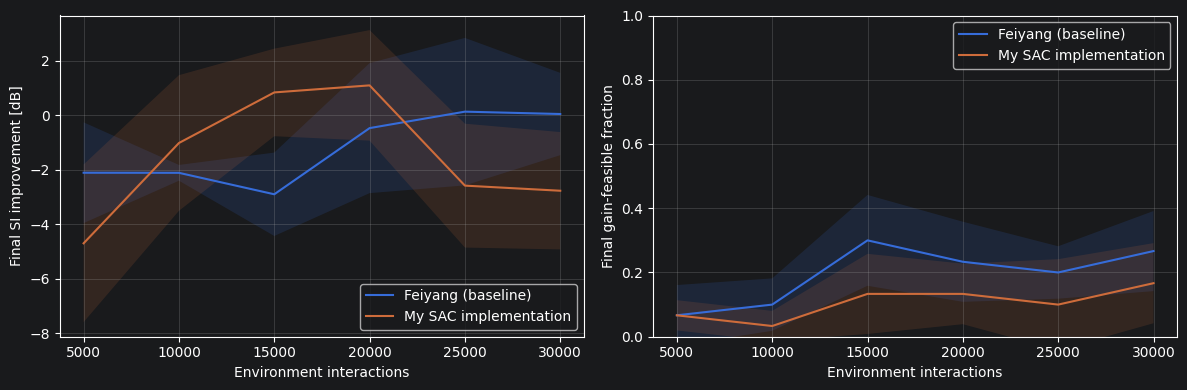

In [12]:
def plot_comparison(results):
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    for name in ['original', 'yours']:
        runs = [r for r in results if r['agent'] == name]
        if not runs or not runs[0]['validation']:
            continue
        steps = np.array([row['step'] for row in runs[0]['validation']])
        for ax, metric in zip(axes, ['final_improvement_mean_dB', 'final_feasible_rate']):
            values = np.array([[row[metric] for row in r['validation']] for r in runs])
            mean, std = values.mean(axis=0), values.std(axis=0)
            if name == 'original':
                ax.plot(steps, mean, label="Feiyang (baseline)")
            else:
                ax.plot(steps, mean, label="My SAC implementation")
            ax.fill_between(steps, mean-std, mean+std, alpha=0.15)
            ax.set_xlabel('Environment interactions')
            ax.grid(alpha=0.3)
            ax.legend()
    axes[0].set_ylabel('Final SI improvement [dB]')
    axes[1].set_ylabel('Final gain-feasible fraction')
    axes[1].set_ylim(0,1)
    fig.tight_layout()
    return fig

plot_comparison(results)
for name in ['original', 'yours']:
     runs = [r for r in results if r['agent'] == name]
     for metric in ['return_mean','final_improvement_mean_dB','final_feasible_rate']:
         values = np.array([r['summary'][metric] for r in runs])
         print(name, metric, 'mean=', values.mean(), 'std across training seeds=', values.std())
